## Sunpy installation and library loading

In [ ]:
!pip install sunpy[net]
!pip install mpl-animators

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 31.3 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [sunpy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
import astropy.units as u
from astropy.coordinates import EarthLocation, SkyCoord
from astropy.time import Time
from sunpy.coordinates import frames
from sunpy.net import Fido, attrs as a
from sunpy.timeseries import TimeSeries
from sunpy.coordinates import GeocentricSolarEcliptic
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import numpy as np
import astropy.units as u
from astropy.time import Time
from astropy.coordinates import SkyCoord, ITRS, CartesianRepresentation, get_sun
from sunpy.coordinates import GeocentricSolarEcliptic

The following packages are not installed:
['cdflib>=1.3.2']
To install sunpy with these dependencies use `pip install sunpy[timeseries]` or `pip install sunpy[all]` for all extras. 
If you installed sunpy via conda, please report this to the community channel: https://matrix.to/#/#sunpy:openastronomy.org [sunpy.util.sysinfo]
The following packages are not installed:
['cdflib>=1.3.2']
To install sunpy with these dependencies use `pip install sunpy[timeseries]` or `pip install sunpy[all]` for all extras. 
If you installed sunpy via conda, please report this to the community channel: https://matrix.to/#/#sunpy:openastronomy.org


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
workdir = '/content/drive/MyDrive/[2025] [Project] November 2025 events/'

Mounted at /content/drive


## Convert asymptotic directions to HEE system

In [ ]:
def convert_asymptotics(geo_lon, geo_lat, timestamp):
    """Geographic (geocentric GEO/ITRS) direction -> GSE lon/lat in degrees.
    Pure direction: accepts scalars or arrays; NaNs are passed through."""
    t = Time(timestamp)
    lon = np.atleast_1d(np.asarray(geo_lon, dtype=float))
    lat = np.atleast_1d(np.asarray(geo_lat, dtype=float))
    out_lon = np.full(lon.shape, np.nan)
    out_lat = np.full(lat.shape, np.nan)

    ok = np.isfinite(lon) & np.isfinite(lat)
    if ok.any():
        lo, la = np.deg2rad(lon[ok]), np.deg2rad(lat[ok])
        r = 1e8  # km; arbitrary, both frames are geocentric so only direction matters
        xyz = CartesianRepresentation(r*np.cos(la)*np.cos(lo),
                                      r*np.cos(la)*np.sin(lo),
                                      r*np.sin(la), unit=u.km)
        gse = SkyCoord(ITRS(xyz, obstime=t)).transform_to(GeocentricSolarEcliptic(obstime=t))
        out_lon[ok] = gse.lon.wrap_at(180*u.deg).deg
        out_lat[ok] = gse.lat.deg

    if np.ndim(geo_lon) == 0:
        return out_lon[0], out_lat[0]
    return out_lon, out_lat

Sun in GSE: lon=-0.0058°, lat=-0.0000°  (expect ~0, ~0)


In [ ]:
timestamp = '2025-11-11T10:30:00'

lons = np.array([-84.39, -71.72, -118.09, -105.82, 137.98, 103.85, 20.39, 28.97, 41.22, 13.19])
lats = np.array([33.75, 42.54, 34.29, 32.78, 36.25, 1.30, 44.86, 41.01, 39.77, 55.71])
rcs = np.array([3.778, 2.402, 4.866, 4.346, 10.728, 17.402, 4.978, 6.334, np.nan, 2.016])

labels=np.array(['Atlanta, GA', 'Leominster, MA', 'Mount Wilson, CA', 'APO, NM', \
                 'Shinshu, Japan', 'Singapore, Singapore', 'Belgrade, Serbia', 'Istanbul, Turkey', \
                 'Erzurum, Turkey', 'Lund, Sweden'])

a07_lat = np.array([-17.8, -10.9, -17.2, -18.2, np.nan, np.nan, -4.5, 11.2, 2.4, 2.5])
a07_lon = np.array([8.7, -8.8, -10.5, -3.1, np.nan, np.nan, 132.9, -132.6, 20.8, 64.5])

a10_lat = np.array([-23.7, -10.6, -33.1, -30.6, np.nan, np.nan, -16.8, -9.1, -2.6, 5.1])
a10_lon = np.array([-6.4, -15.8, -38.6, -25.5, np.nan, np.nan, 103.7, 141.1, 165.1, 56.1])

a20_lat = np.array([2.4, 14.6, -6.5, -4.7, -12.2, 0.4, 6.2, 0.5, -1.6, 24.7])
a20_lon = np.array([-32.6, -24.0, -71.4, -57.3, -147.9, -117.4, 73.4, 87.5, 101.9, 55.2])

a07_lat_conv = np.zeros_like(a07_lat)
a07_lon_conv = np.zeros_like(a07_lon)
a10_lat_conv = np.zeros_like(a10_lat)
a10_lon_conv = np.zeros_like(a10_lon)
a20_lat_conv = np.zeros_like(a20_lat)
a20_lon_conv = np.zeros_like(a20_lon)

for i in range (0, len(a10_lat)):
  a07_lon_conv[i], a07_lat_conv[i] = convert_asymptotics(a07_lon[i], a07_lat[i], timestamp)
  a10_lon_conv[i], a10_lat_conv[i] = convert_asymptotics(a10_lon[i], a10_lat[i], timestamp)
  a20_lon_conv[i], a20_lat_conv[i] = convert_asymptotics(a20_lon[i], a20_lat[i], timestamp)

## Note of the solar wind

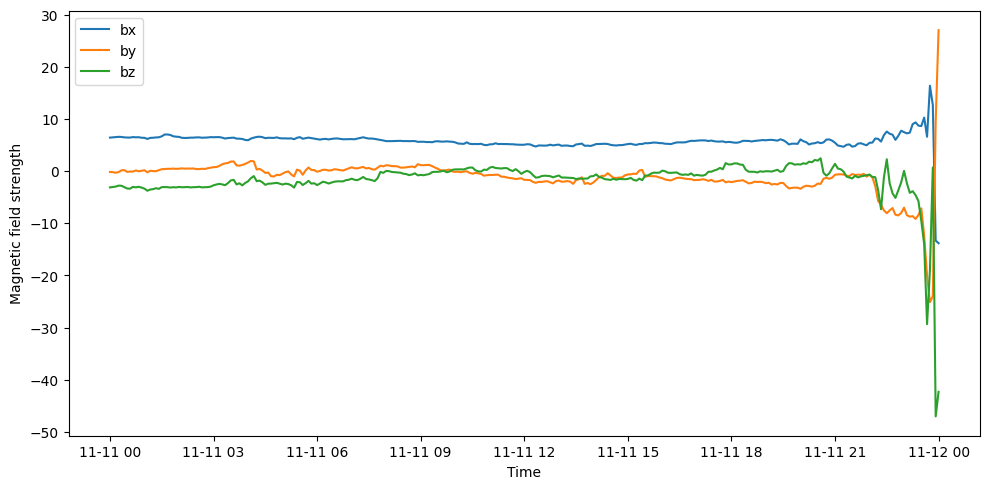

In [ ]:
fname = workdir + 'AC_K0_MFI_4167890.txt'

rows = [l.split() for l in open(fname) if l[:1].isdigit()]   # data rows start with dd-mm-yyyy
df = pd.DataFrame(rows, columns=['date', 'time', 'b', 'bx', 'by', 'bz'])
df.index = pd.to_datetime(df.date + ' ' + df.time, format='%d-%m-%Y %H:%M:%S.%f')
df = df[['b', 'bx', 'by', 'bz']].astype(float)

fig, ax = plt.subplots(figsize=(10, 5))
for c in ['bx', 'by', 'bz']:
    ax.plot(df.index, df[c], label=c)
ax.set_xlabel('Time')
ax.set_ylabel('Magnetic field strength')
ax.legend(loc='upper left')
plt.tight_layout()

In [ ]:
ace_subset = df.between_time('10:10', '10:50')

print("Average bx:", ace_subset['bx'].mean())
print("Average by:", ace_subset['by'].mean())
print("Average bz:", ace_subset['bz'].mean())

Average bx: 5.258777777777777
Average by: -0.34744444444444444
Average bz: 0.34400000000000003


## Visualization of asymptotic directions and impact

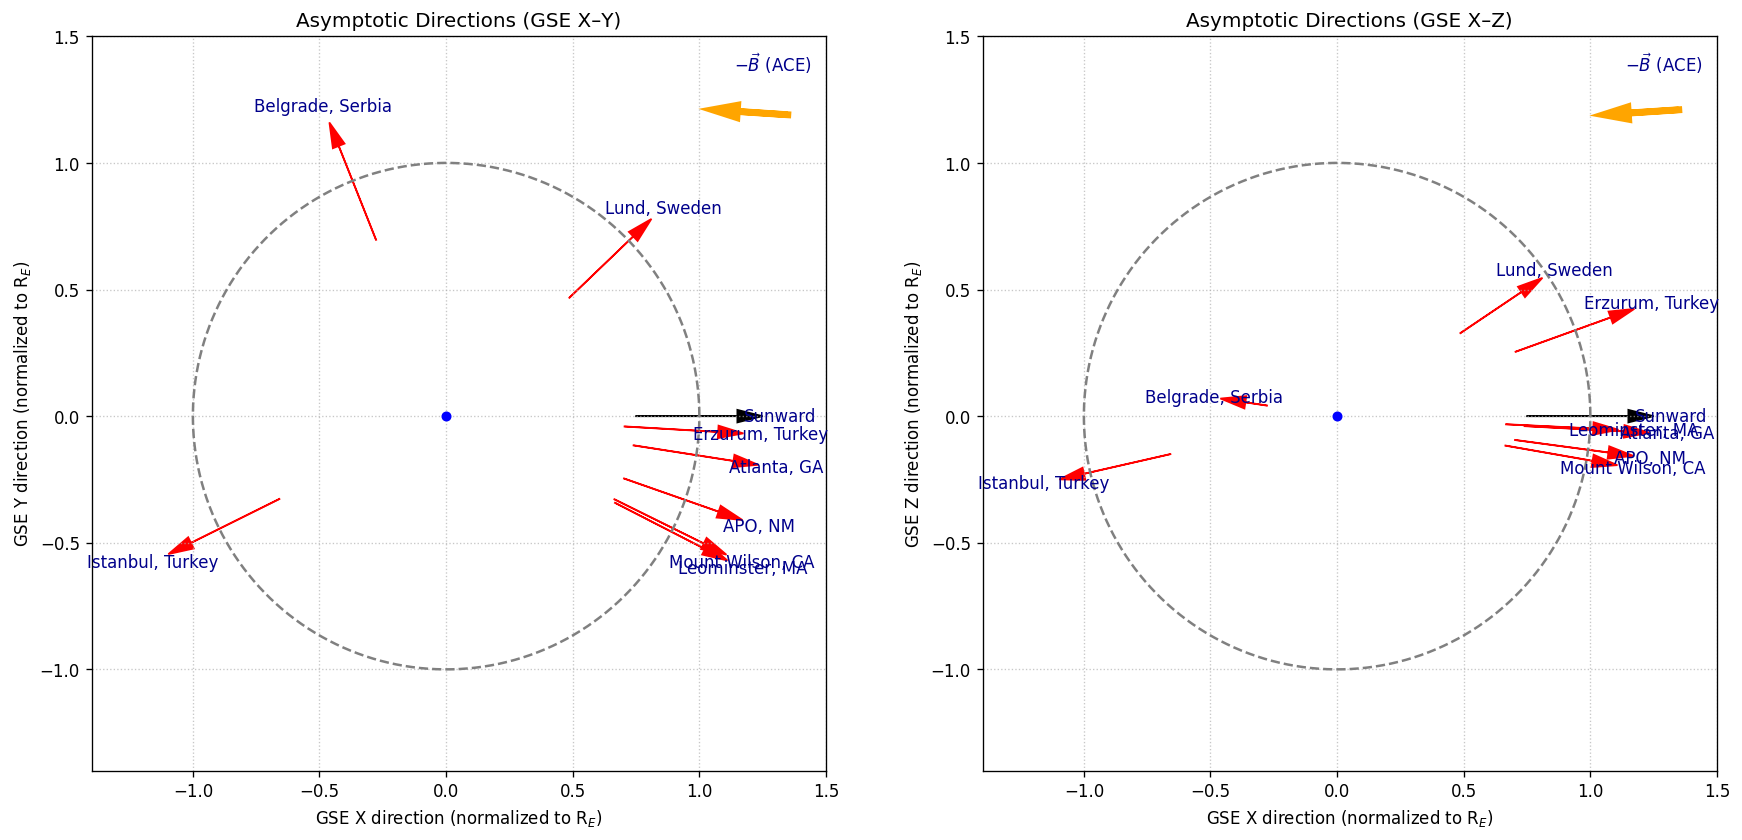

In [ ]:
B_SIGN = -1

def unit_vec(lon_deg, lat_deg):
    lon, lat = np.deg2rad(lon_deg), np.deg2rad(lat_deg)
    return np.cos(lat)*np.cos(lon), np.cos(lat)*np.sin(lon), np.sin(lat)

def draw_direction(ax, h, v, label, color, r0=0.75, r1=1.25):
    """Arrow along the projected direction (h, v) of a unit vector."""
    ax.arrow(r0*h, r0*v, (r1 - r0)*h, (r1 - r0)*v,
             head_width=0.05, head_length=0.1, length_includes_head=True,
             fc=color, ec=color, linewidth=1)
    ax.text(1.32*h, 1.32*v, label, color='darkblue', fontsize=10,
            ha='center', va='center')

def draw_bfield(ax, bh, bv, center=(1.2, 1.2), length=0.3):
    """Fixed-length arrow showing the in-plane direction of the mean field."""
    mag = np.hypot(bh, bv)
    if not np.isfinite(mag) or mag == 0:
        return
    dh, dv = length*bh/mag, length*bv/mag
    ax.arrow(center[0] - dh/2, center[1] - dv/2, dh, dv,
             head_width=0.05, head_length=0.1, length_includes_head=True,
             fc='orange', ec='orange', linewidth=4)

# Direction unit vectors in GSE
gx, gy, gz = unit_vec(np.asarray(a07_lon_conv, float), np.asarray(a07_lat_conv, float))
valid = np.isfinite(gx) & np.isfinite(gy) & np.isfinite(gz)

# Mean IMF (GSE) over the interval
bx, by, bz = (B_SIGN * ace_subset[c].mean() for c in ('bx', 'by', 'bz'))
b_label = (r'$\vec{B}$ (ACE)' if B_SIGN > 0
           else r'$-\vec{B}$ (ACE)')

panels = [
    (gx, gy, (bx, by), r'GSE Y direction (normalized to R$_{E}$)',
     'Asymptotic Directions (GSE X–Y)'),
    (gx, gz, (bx, bz), r'GSE Z direction (normalized to R$_{E}$)',
     'Asymptotic Directions (GSE X–Z)'),
]

theta = np.linspace(0, 2*np.pi, 200)
fig, axes = plt.subplots(1, 2, figsize=(15, 7), dpi=120)

for ax, (h, v, (bh, bv), ylabel, title) in zip(axes, panels):
    ax.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--',
            label='Unit sphere projection')
    ax.plot(0, 0, 'o', color='blue', markersize=5, label='Earth')

    draw_direction(ax, 1.0, 0.0, 'Sunward', 'black')   # GSE +X
    for i in np.flatnonzero(valid):
        draw_direction(ax, h[i], v[i], labels[i], 'red')

    draw_bfield(ax, bh, bv)
    ax.text(0.98, 0.98, b_label, color='darkblue', fontsize=10,
            ha='right', va='top', transform=ax.transAxes)

    ax.set_xlim(-1.4, 1.5)
    ax.set_ylim(-1.4, 1.5)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(True, linestyle=':', alpha=0.7)
    ax.set_xlabel(r'GSE X direction (normalized to R$_{E}$)', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=12)

plt.tight_layout()
plt.savefig('asymptotic_directions_r1_07GEV.svg', format='svg')
plt.show()

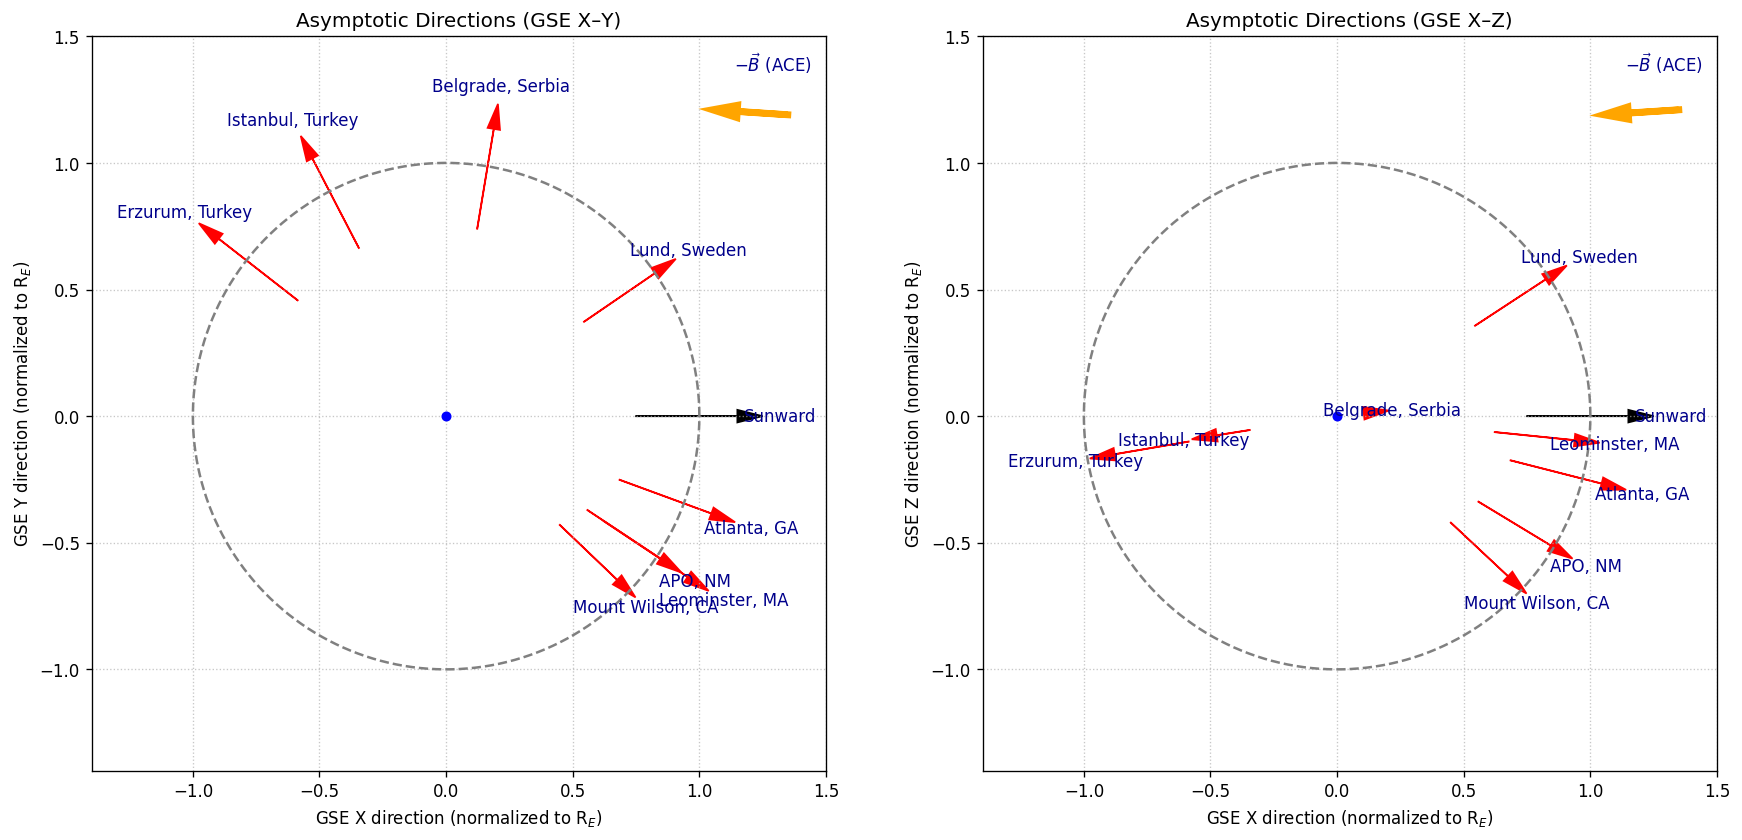

In [ ]:
B_SIGN = -1

def unit_vec(lon_deg, lat_deg):
    lon, lat = np.deg2rad(lon_deg), np.deg2rad(lat_deg)
    return np.cos(lat)*np.cos(lon), np.cos(lat)*np.sin(lon), np.sin(lat)

def draw_direction(ax, h, v, label, color, r0=0.75, r1=1.25):
    """Arrow along the projected direction (h, v) of a unit vector."""
    ax.arrow(r0*h, r0*v, (r1 - r0)*h, (r1 - r0)*v,
             head_width=0.05, head_length=0.1, length_includes_head=True,
             fc=color, ec=color, linewidth=1)
    ax.text(1.32*h, 1.32*v, label, color='darkblue', fontsize=10,
            ha='center', va='center')

def draw_bfield(ax, bh, bv, center=(1.2, 1.2), length=0.3):
    """Fixed-length arrow showing the in-plane direction of the mean field."""
    mag = np.hypot(bh, bv)
    if not np.isfinite(mag) or mag == 0:
        return
    dh, dv = length*bh/mag, length*bv/mag
    ax.arrow(center[0] - dh/2, center[1] - dv/2, dh, dv,
             head_width=0.05, head_length=0.1, length_includes_head=True,
             fc='orange', ec='orange', linewidth=4)

# Direction unit vectors in GSE
gx, gy, gz = unit_vec(np.asarray(a10_lon_conv, float), np.asarray(a10_lat_conv, float))
valid = np.isfinite(gx) & np.isfinite(gy) & np.isfinite(gz)

# Mean IMF (GSE) over the interval
bx, by, bz = (B_SIGN * ace_subset[c].mean() for c in ('bx', 'by', 'bz'))
b_label = (r'$\vec{B}$ (ACE)' if B_SIGN > 0
           else r'$-\vec{B}$ (ACE)')

panels = [
    (gx, gy, (bx, by), r'GSE Y direction (normalized to R$_{E}$)',
     'Asymptotic Directions (GSE X–Y)'),
    (gx, gz, (bx, bz), r'GSE Z direction (normalized to R$_{E}$)',
     'Asymptotic Directions (GSE X–Z)'),
]

theta = np.linspace(0, 2*np.pi, 200)
fig, axes = plt.subplots(1, 2, figsize=(15, 7), dpi=120)

for ax, (h, v, (bh, bv), ylabel, title) in zip(axes, panels):
    ax.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--',
            label='Unit sphere projection')
    ax.plot(0, 0, 'o', color='blue', markersize=5, label='Earth')

    draw_direction(ax, 1.0, 0.0, 'Sunward', 'black')   # GSE +X
    for i in np.flatnonzero(valid):
        draw_direction(ax, h[i], v[i], labels[i], 'red')

    draw_bfield(ax, bh, bv)
    ax.text(0.98, 0.98, b_label, color='darkblue', fontsize=10,
            ha='right', va='top', transform=ax.transAxes)

    ax.set_xlim(-1.4, 1.5)
    ax.set_ylim(-1.4, 1.5)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(True, linestyle=':', alpha=0.7)
    ax.set_xlabel(r'GSE X direction (normalized to R$_{E}$)', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=12)

plt.tight_layout()
plt.savefig('asymptotic_directions_r1_10GEV.svg', format='svg')
plt.show()

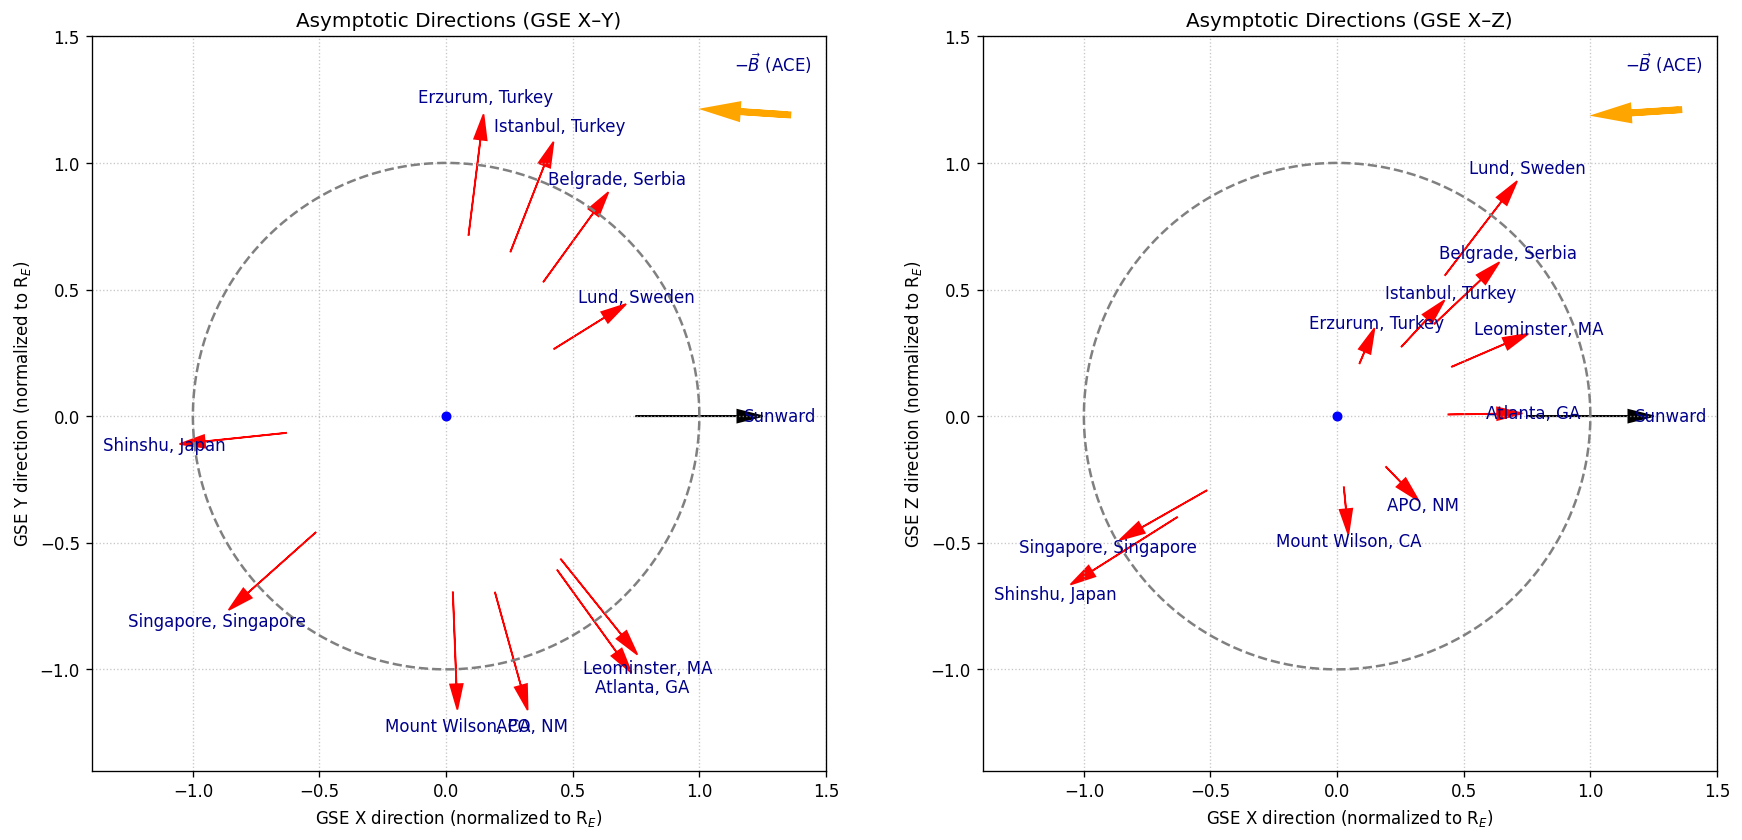

In [ ]:
B_SIGN = -1

def unit_vec(lon_deg, lat_deg):
    lon, lat = np.deg2rad(lon_deg), np.deg2rad(lat_deg)
    return np.cos(lat)*np.cos(lon), np.cos(lat)*np.sin(lon), np.sin(lat)

def draw_direction(ax, h, v, label, color, r0=0.75, r1=1.25):
    """Arrow along the projected direction (h, v) of a unit vector."""
    ax.arrow(r0*h, r0*v, (r1 - r0)*h, (r1 - r0)*v,
             head_width=0.05, head_length=0.1, length_includes_head=True,
             fc=color, ec=color, linewidth=1)
    ax.text(1.32*h, 1.32*v, label, color='darkblue', fontsize=10,
            ha='center', va='center')

def draw_bfield(ax, bh, bv, center=(1.2, 1.2), length=0.3):
    """Fixed-length arrow showing the in-plane direction of the mean field."""
    mag = np.hypot(bh, bv)
    if not np.isfinite(mag) or mag == 0:
        return
    dh, dv = length*bh/mag, length*bv/mag
    ax.arrow(center[0] - dh/2, center[1] - dv/2, dh, dv,
             head_width=0.05, head_length=0.1, length_includes_head=True,
             fc='orange', ec='orange', linewidth=4)

# Direction unit vectors in GSE
gx, gy, gz = unit_vec(np.asarray(a20_lon_conv, float), np.asarray(a20_lat_conv, float))
valid = np.isfinite(gx) & np.isfinite(gy) & np.isfinite(gz)

# Mean IMF (GSE) over the interval
bx, by, bz = (B_SIGN * ace_subset[c].mean() for c in ('bx', 'by', 'bz'))
b_label = (r'$\vec{B}$ (ACE)' if B_SIGN > 0
           else r'$-\vec{B}$ (ACE)')

panels = [
    (gx, gy, (bx, by), r'GSE Y direction (normalized to R$_{E}$)',
     'Asymptotic Directions (GSE X–Y)'),
    (gx, gz, (bx, bz), r'GSE Z direction (normalized to R$_{E}$)',
     'Asymptotic Directions (GSE X–Z)'),
]

theta = np.linspace(0, 2*np.pi, 200)
fig, axes = plt.subplots(1, 2, figsize=(15, 7), dpi=120)

for ax, (h, v, (bh, bv), ylabel, title) in zip(axes, panels):
    ax.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--',
            label='Unit sphere projection')
    ax.plot(0, 0, 'o', color='blue', markersize=5, label='Earth')

    draw_direction(ax, 1.0, 0.0, 'Sunward', 'black')   # GSE +X
    for i in np.flatnonzero(valid):
        draw_direction(ax, h[i], v[i], labels[i], 'red')

    draw_bfield(ax, bh, bv)
    ax.text(0.98, 0.98, b_label, color='darkblue', fontsize=10,
            ha='right', va='top', transform=ax.transAxes)

    ax.set_xlim(-1.4, 1.5)
    ax.set_ylim(-1.4, 1.5)
    ax.set_aspect('equal', adjustable='box')
    ax.grid(True, linestyle=':', alpha=0.7)
    ax.set_xlabel(r'GSE X direction (normalized to R$_{E}$)', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontsize=12)

plt.tight_layout()
plt.savefig('asymptotic_directions_r1_20GEV.svg', format='svg')
plt.show()

Computing angle alignment with solar wind

In [ ]:
def unit_vec(lon_deg, lat_deg):
    lon, lat = np.deg2rad(lon_deg), np.deg2rad(lat_deg)
    return np.stack([np.cos(lat)*np.cos(lon),
                     np.cos(lat)*np.sin(lon),
                     np.sin(lat)], axis=-1)

def sunward_field_dir(bx, by, bz, warn_deg=15):
    """Unit vector along the IMF line pointing toward the Sun (+X side)."""
    b = np.array([bx, by, bz], float)
    b /= np.linalg.norm(b)
    if b[0] < 0:
        b = -b
    if np.degrees(np.arcsin(abs(b[0]))) < warn_deg:
        print(f'Warning: field nearly perpendicular to Sun-Earth line '
              f'(|Bx|/|B| = {abs(b[0]):.2f}); sunward sign is ambiguous.')
    return b

def alignment_table(lon_deg, lat_deg, names, b_sun, rigidity=None):
    g = unit_vec(np.asarray(lon_deg, float), np.asarray(lat_deg, float))
    cos_b = np.clip(g @ b_sun, -1, 1)
    df = pd.DataFrame({
        'station': names,
        'lon_GSE': lon_deg, 'lat_GSE': lat_deg,
        'angle_to_sunward_IMF_deg': np.degrees(np.arccos(cos_b)),
        'angle_to_IMF_line_deg': np.degrees(np.arccos(np.abs(cos_b))),
        'angle_to_sunward_X_deg': np.degrees(np.arccos(np.clip(g[:, 0], -1, 1))),
    })
    if rigidity is not None:
        df.insert(1, 'R_GV', rigidity)
    return df.sort_values('angle_to_sunward_IMF_deg').reset_index(drop=True)

# ---- mean IMF over the interval (GSE) ----
bx, by, bz = (ace_subset[c].mean() for c in ('bx', 'by', 'bz'))
b_sun = sunward_field_dir(bx, by, bz)
print('Sunward IMF unit vector (GSE):', np.round(b_sun, 3),
      f'| lon = {np.degrees(np.arctan2(b_sun[1], b_sun[0])):.1f} deg,'
      f' lat = {np.degrees(np.arcsin(b_sun[2])):.1f} deg')

# ---- printing values ----
tab07 = alignment_table(a07_lon_conv, a07_lat_conv, labels, b_sun, rigidity=7)
print(tab07.round(1))
tab10 = alignment_table(a10_lon_conv, a10_lat_conv, labels, b_sun, rigidity=10)
print(tab10.round(1))
tab20 = alignment_table(a20_lon_conv, a20_lat_conv, labels, b_sun, rigidity=20)
print(tab20.round(1))

Sunward IMF unit vector (GSE): [ 0.996 -0.066  0.065] | lon = -3.8 deg, lat = 3.7 deg
                station  R_GV  lon_GSE  lat_GSE  angle_to_sunward_IMF_deg  \
0           Atlanta, GA     7     -8.9     -3.0                       8.4   
1       Erzurum, Turkey     7     -3.3     19.8                      16.1   
2               APO, NM     7    -19.3     -7.2                      19.0   
3        Leominster, MA     7    -27.2     -2.5                      24.2   
4      Mount Wilson, CA     7    -26.3     -8.9                      25.8   
5          Lund, Sweden     7     43.8     25.9                      50.7   
6      Belgrade, Serbia     7    111.7      3.2                     115.1   
7      Istanbul, Turkey     7   -153.6    -11.5                     149.1   
8        Shinshu, Japan     7      NaN      NaN                       NaN   
9  Singapore, Singapore     7      NaN      NaN                       NaN   

   angle_to_IMF_line_deg  angle_to_sunward_X_deg  
0              

# Working with 1-minute cadence data (for GLE visualization)

In [ ]:
muonfile = workdir + 'Release Codes/one_minute_data/' + 'APO_raw.csv'
data = pd.read_csv(muonfile)
data_date = np.array(data['datetime'])
data_pc = np.array(data['counts12'])

In [ ]:
goesfile = workdir + 'Release Codes/goes19sgps_nov2025.nc'

ds_goes = xr.open_dataset(goesfile)

In [ ]:
goes_time = np.array(ds_goes['time'])
print(goes_time.shape)
print(goes_time)
flux_observed = np.array(ds_goes['AvgDiffProtonFluxObserved'])
flux_observed.shape
energy_eff = np.array(ds_goes['DiffProtonEffectiveEnergy'])
print(energy_eff.shape, energy_eff[0,0,:])

goes_323e = flux_observed[:,0,-1]
goes_323w = flux_observed[:,1,-1]

(24480,)
['2025-11-01T00:00:00.000000000' '2025-11-01T00:01:00.000000000'
 '2025-11-01T00:02:00.000000000' ... '2025-11-17T23:57:00.000000000'
 '2025-11-17T23:58:00.000000000' '2025-11-17T23:59:00.000000000']
(24480, 2, 13) [  1377.3888   2090.4546   2777.661    4693.8257   8014.986   16457.91
  30194.04    55081.758   91422.65   109046.59   127075.414  189548.94
 322691.8   ]


In [ ]:
pressure_corrected_folder = workdir + 'Release Codes/one_minute_data/'

filenames_pc = ['APO_raw.csv', 'California_raw.csv', 'Erzurum_raw.csv', 'Istanbul_raw.csv', 'Lund_raw.csv', \
                'Atlanta_1PP.csv', 'Atlanta_rm415_raw.csv', 'Shinshu_raw.csv', 'Massachussetts_raw.csv', 'Belgrade_ground_raw.csv', 'Singapore_raw.csv']

labels_pc = ['Apache Point Observatory, NM', 'Mount Wilson, CA', 'Erzurum, Turkey', 'Istanbul, Turkey', 'Lund, Sweden', \
             'Atlanta (detector 1), GA', 'Atlanta (detector 2), GA', 'Shinshu, Japan', 'Leominster, MA', 'Belgrade, Serbia', 'Singapore, Singapore']

# reading muon data
def muon_filereader(muonfile):
  data = pd.read_csv(muonfile)
  data['datetime'] = pd.to_datetime(data['datetime'])
  data = data.set_index('datetime')
  date_start = pd.to_datetime('2025-11-09 00:00:00').tz_localize('UTC')
  date_end = pd.to_datetime('2025-11-15 00:00:00').tz_localize('UTC')
  data = data[(data.index >= date_start) & (data.index <= date_end)]
  # 20-minute averages, with bins anchored at :00, :20, :40 (left edge of each bin)
  data_resampled = data['counts12'].resample('20min', label='left', origin='start_day').mean()
  # shift timestamps to the center of each 20-minute interval (+10 min)
  data_date = np.array(data_resampled.index + pd.Timedelta(minutes=10))
  data_pc = np.array(data_resampled.values)
  # remove empty bins (no data in the 20-min window)
  mask = ~np.isnan(data_pc)
  data_date = data_date[mask]
  data_pc = data_pc[mask]
  return data_date, data_pc

# loading GOES data
goesfile = workdir + 'Release Codes/goes19sgps_nov2025.nc'
ds_goes = xr.open_dataset(goesfile)
goes_time = np.array(ds_goes['time'])
flux_observed = np.array(ds_goes['AvgDiffProtonFluxObserved'])
goes_323e = flux_observed[:,0,-1]
goes_323w = flux_observed[:,1,-1]

goes_time_5min = goes_time[3::5]
goes_323e_5min = np.zeros([17*24*12], dtype=float)
goes_323w_5min = np.zeros([17*24*12], dtype=float)
for i in range (0, 17*24*12, 1):
  goes_323e_5min[i] = np.nanmean(goes_323e[i*5:i*5+5])
  goes_323w_5min[i] = np.nanmean(goes_323w[i*5:i*5+5])


date_start = pd.to_datetime('2025-11-09 00:00:00')
date_end = pd.to_datetime('2025-11-15 00:00:00')
indexes = np.where(((goes_time_5min >= date_start) & (goes_time_5min <= date_end)))
goes_time_5min = goes_time_5min[indexes]
goes_323e_5min = goes_323e_5min[indexes]
goes_323w_5min = goes_323w_5min[indexes]

In [ ]:
nm_data = pd.read_csv(
    workdir + 'Release Codes/NeutronMonitor_10min.csv',
    skiprows=1,
    names=['nm_datetime', 'MXCO', 'OULU', 'SOPO'],
    delimiter=';',
    na_values=['null']
)
# Convert 'nm_datetime' to datetime objects
nm_data['nm_datetime'] = pd.to_datetime(nm_data['nm_datetime'])

# Convert 'MXCO', 'OULU', 'SOPO' to float
nm_data['OULU'] = pd.to_numeric(nm_data['OULU'])
nm_data['SOPO'] = pd.to_numeric(nm_data['SOPO'])

nm_time_1h = np.array(nm_data['nm_datetime'])
nm_oulu = np.array(nm_data['OULU'])

In [ ]:
x_flares = [\
pd.to_datetime('2025-11-09  07:01:00'), \
pd.to_datetime('2025-11-10  08:55:00'), \
pd.to_datetime('2025-11-11  09:49:00'), \
pd.to_datetime('2025-11-14  07:44:00'), \
]

fast_CMEs_750 = [\
pd.to_datetime('2025-11-09  21:12:00'), \
pd.to_datetime('2025-11-10  09:36:00'), \
pd.to_datetime('2025-11-11  10:23:00'), \
pd.to_datetime('2025-11-11  14:45:00'), \
pd.to_datetime('2025-11-13  03:24:00'), \
pd.to_datetime('2025-11-14  01:25:00'), \
pd.to_datetime('2025-11-14  08:00:00'), \
]

ICMEs = [\
pd.to_datetime('2025-11-09  18:05:00'), \
pd.to_datetime('2025-11-11  22:11:00'), \
pd.to_datetime('2025-11-12  18:52:00'), \
]

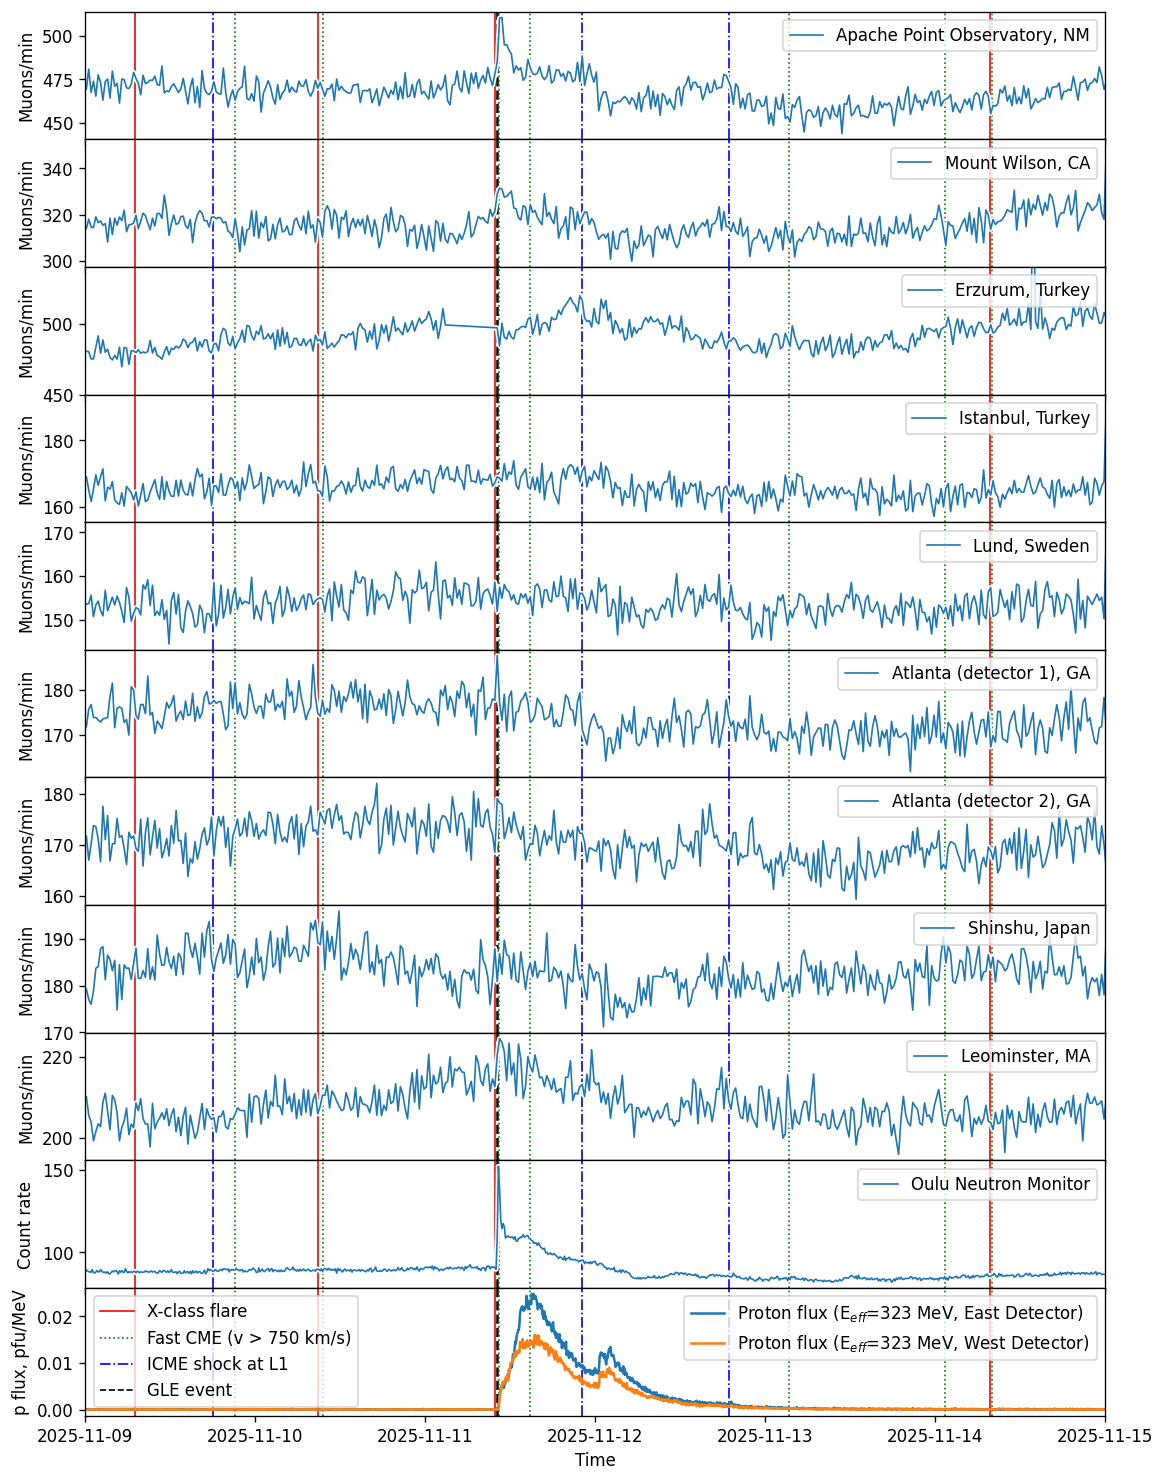

In [ ]:
# reading muon data
def muon_filereader_20(muonfile):
  data = pd.read_csv(muonfile)
  data['datetime'] = pd.to_datetime(data['datetime'])
  data = data.set_index('datetime')
  date_start = pd.to_datetime('2025-11-09 00:00:00').tz_localize('UTC')
  date_end = pd.to_datetime('2025-11-15 00:00:00').tz_localize('UTC')
  data = data[(data.index >= date_start) & (data.index <= date_end)]
  # 20-minute averages, with bins anchored at :00, :20, :40 (left edge of each bin)
  data_resampled = data['counts12'].resample('20min', label='left', origin='start_day').mean()
  # shift timestamps to the center of each 20-minute interval (+10 min)
  data_date = np.array(data_resampled.index + pd.Timedelta(minutes=10))
  data_pc = np.array(data_resampled.values)
  # remove empty bins (no data in the 20-min window)
  mask = ~np.isnan(data_pc)
  data_date = data_date[mask]
  data_pc = data_pc[mask]
  return data_date, data_pc

from matplotlib.lines import Line2D

im, ax = plt.subplots(11, 1, figsize=(10,13), dpi=120, sharex=True)

for i in range (0, 9, 1):
  data_date, data_pc = muon_filereader_20(pressure_corrected_folder + filenames_pc[i])
  ax[i].axvline(pd.to_datetime('2025-11-11 10:10:00'), color='k', linestyle='--') # Add vertical line
  for x_flare_time in x_flares:
    ax[i].axvline(x_flare_time, color='red', linestyle='-', lw=1)
  for cme_time in fast_CMEs_750:
    ax[i].axvline(cme_time, color='green', linestyle=':', lw=1)
  for icme_time in ICMEs:
    ax[i].axvline(icme_time, color='blue', linestyle='-.', lw=1)
  ax[i].plot(data_date, data_pc, color='white', lw=3.0)
  ax[i].plot(data_date, data_pc, label=labels_pc[i], lw=1.0)
  ax[i].set(ylabel='Muons/min', xlim=[date_start,date_end])#, ylim=[-7.5,7.5])
  if (i == 2): ax[i].set(ylim=[450,540])
  ax[i].legend(loc=1)
  ax[i].tick_params(labelbottom=False) # Hide x-axis labels for upper plots

# New panel for Oulu Neutron Monitor
ax[9].axvline(pd.to_datetime('2025-11-11 10:10:00'), color='k', linestyle='--')
for x_flare_time in x_flares:
  ax[9].axvline(x_flare_time, color='red', linestyle='-', lw=1)
for cme_time in fast_CMEs_750:
  ax[9].axvline(cme_time, color='green', linestyle=':', lw=1)
for icme_time in ICMEs:
  ax[9].axvline(icme_time, color='blue', linestyle='-.', lw=1)
ax[9].plot(nm_time_1h, nm_oulu, color='white', lw=3.0)
ax[9].plot(nm_time_1h, nm_oulu, label='Oulu Neutron Monitor', lw=1.0)
ax[9].set(ylabel='Count rate', xlim=[date_start,date_end])
ax[9].legend(loc=1)
ax[9].tick_params(labelbottom=False)

ax[10].axvline(pd.to_datetime('2025-11-11 10:10:00'), color='k', linestyle='--')
for x_flare_time in x_flares:
  ax[10].axvline(x_flare_time, color='red', linestyle='-', lw=1)
for cme_time in fast_CMEs_750:
  ax[10].axvline(cme_time, color='green', linestyle=':', lw=1)
for icme_time in ICMEs:
  ax[10].axvline(icme_time, color='blue', linestyle='-.', lw=1)
line_east, = ax[10].plot(goes_time_5min, goes_323e_5min*1e3, label=r'Proton flux (E$_{eff}$=323 MeV, East Detector)')
line_west, = ax[10].plot(goes_time_5min, goes_323w_5min*1e3, label=r'Proton flux (E$_{eff}$=323 MeV, West Detector)')
ax[10].set(xlabel='Time', ylabel=r'p flux, pfu/MeV', xlim=[date_start,date_end])
leg1 = ax[10].legend(handles=[line_east, line_west], loc=1)
custom_lines = [
    Line2D([0], [0], color='red', lw=1, linestyle='-'),
    Line2D([0], [0], color='green', lw=1, linestyle=':'),
    Line2D([0], [0], color='blue', lw=1, linestyle='-.'),
    Line2D([0], [0], color='black', lw=1, linestyle='--')
]
leg2 = ax[10].legend(custom_lines, ['X-class flare', r'Fast CME (v > 750 km/s)', 'ICME shock at L1', 'GLE event'], loc=2)
ax[10].add_artist(leg1)

# Rotate y-axis labels for better visibility
#for i in range(11):
#    ax[i].set_ylabel(ax[i].get_ylabel(), rotation=80, ha='center') # Rotate actual y-label

# Adjust spacing between subplots and figure edges, providing some bottom, left, and right margin
im.subplots_adjust(hspace=0, wspace=0, left=0.1, right=0.95, top=0.95, bottom=0.05)
plt.savefig('muon_flux_comparison_20min_r1.png')
plt.show()

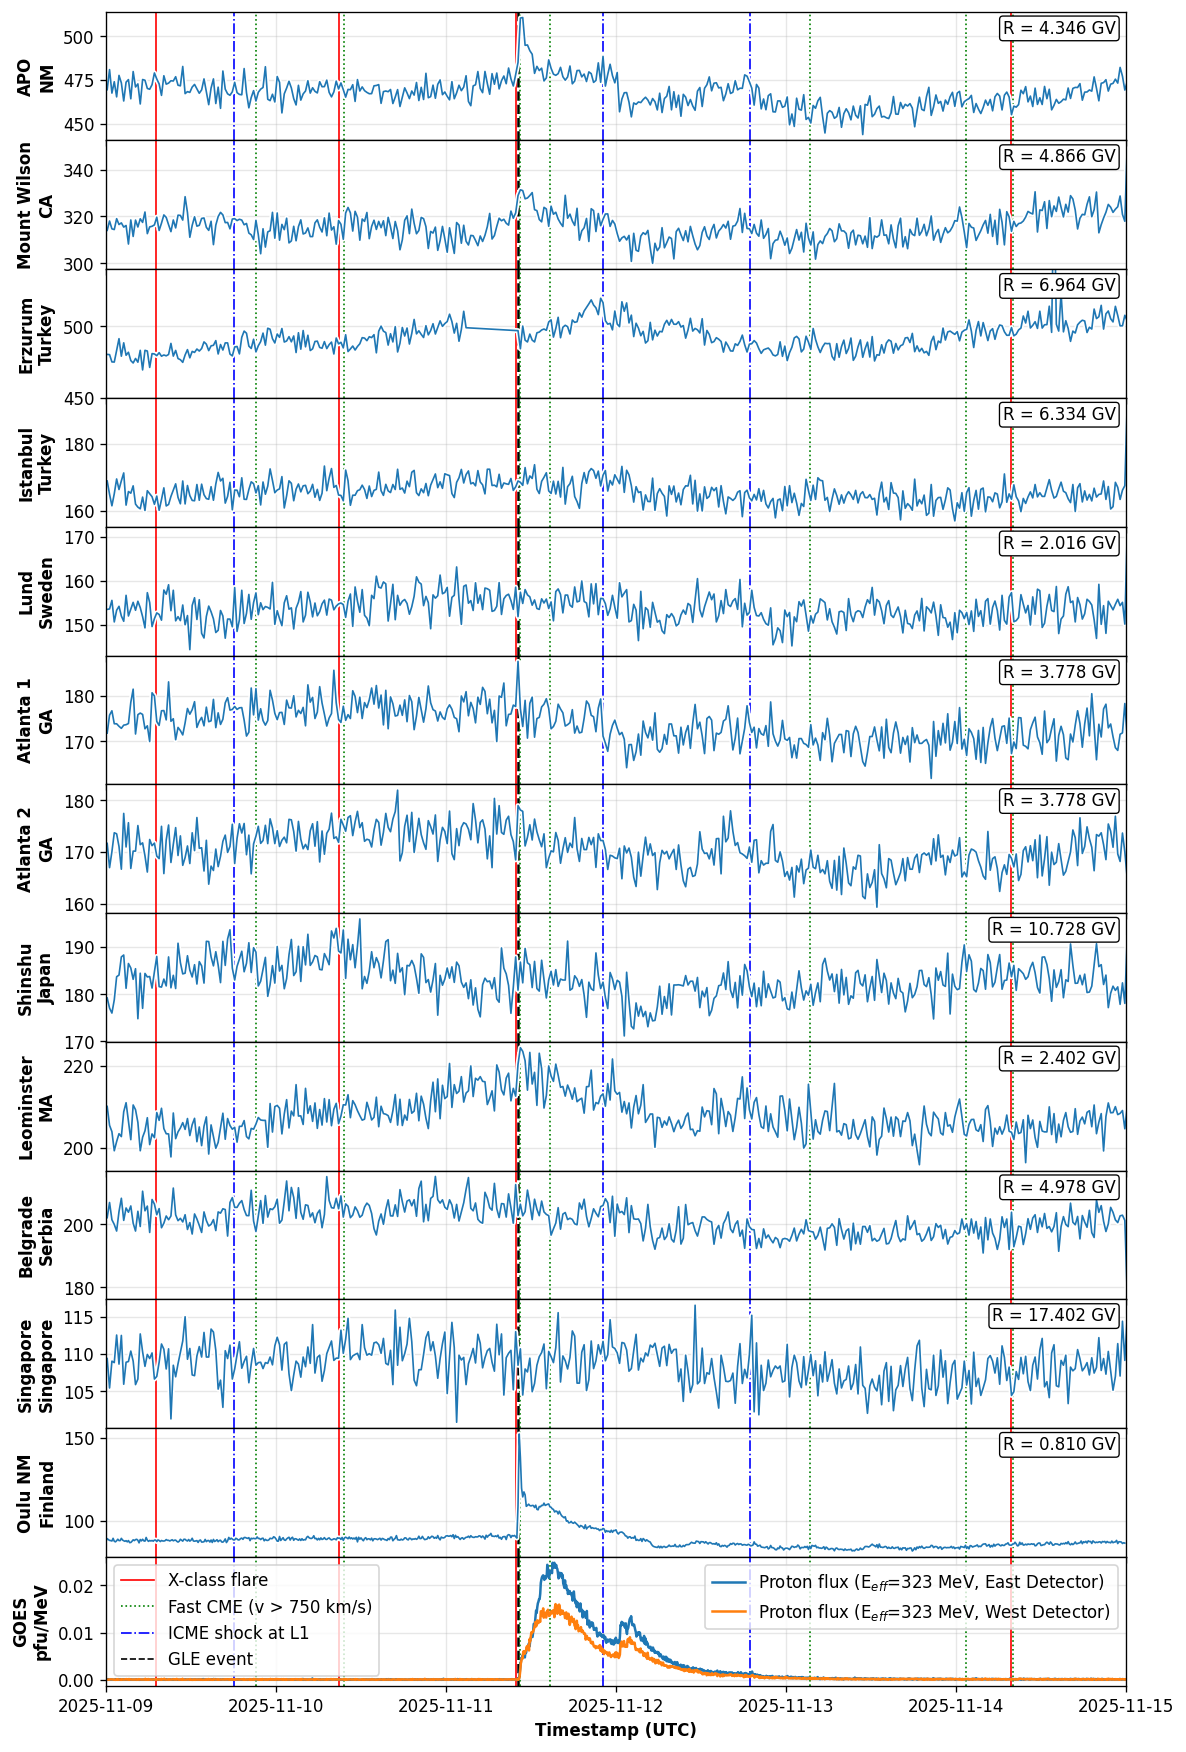

In [ ]:
from matplotlib.lines import Line2D

# Side labels (name / region), same order as filenames_pc
stations_pc = ['APO\nNM', 'Mount Wilson\nCA', 'Erzurum\nTurkey', 'Istanbul\nTurkey',
               'Lund\nSweden', 'Atlanta 1\nGA', 'Atlanta 2\nGA',
               'Shinshu\nJapan', 'Leominster\nMA', 'Belgrade\nSerbia', 'Singapore\nSingapore']
rc_pc = [4.346, 4.866, 6.964, 6.334, 2.016, 3.778, 3.778, 10.728, 2.402, 4.978, 17.402]  # GV

date_start = pd.Timestamp('2025-11-09 00:00:00', tz='UTC')
date_end   = pd.Timestamp('2025-11-15 00:00:00', tz='UTC')
gle_time   = pd.Timestamp('2025-11-11 10:10:00', tz='UTC')

def add_events(ax):
    ax.axvline(gle_time, color='k', linestyle='--')
    for t in x_flares:      ax.axvline(t, color='red',   linestyle='-',  lw=1)
    for t in fast_CMEs_750: ax.axvline(t, color='green', linestyle=':',  lw=1)
    for t in ICMEs:         ax.axvline(t, color='blue',  linestyle='-.', lw=1)

def style_panel(ax, label, rc=None):
    ax.set_ylabel(label, fontweight='bold')
    ax.grid(True, alpha=0.3)
    if rc is not None:
        ax.text(0.99, 0.94, f'R = {rc:.3f} GV', transform=ax.transAxes,
                ha='right', va='top',
                bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='k', lw=0.8))

n = len(filenames_pc)
fig, ax = plt.subplots(n + 2, 1, figsize=(10, 15), dpi=120, sharex=True)

# Muon detectors
for i in range(n):
    t, y = muon_filereader_20(pressure_corrected_folder + filenames_pc[i])
    add_events(ax[i])
    ax[i].plot(t, y, color='white', lw=3.0)
    ax[i].plot(t, y, lw=1.0)
    style_panel(ax[i], stations_pc[i], rc_pc[i])
    if i == 2:
        ax[i].set_ylim(450, 540)

# Oulu NM
add_events(ax[n])
ax[n].plot(nm_time_1h, nm_oulu, color='white', lw=3.0)
ax[n].plot(nm_time_1h, nm_oulu, lw=1.0)
style_panel(ax[n], 'Oulu NM\nFinland', 0.81)

# GOES (original legends preserved)
a = ax[n + 1]
add_events(a)
line_east, = a.plot(goes_time_5min, goes_323e_5min*1e3,
                    label=r'Proton flux (E$_{eff}$=323 MeV, East Detector)')
line_west, = a.plot(goes_time_5min, goes_323w_5min*1e3,
                    label=r'Proton flux (E$_{eff}$=323 MeV, West Detector)')
style_panel(a, 'GOES\npfu/MeV')
leg1 = a.legend(handles=[line_east, line_west], loc=1)
custom_lines = [Line2D([0], [0], color='red',   lw=1, linestyle='-'),
                Line2D([0], [0], color='green', lw=1, linestyle=':'),
                Line2D([0], [0], color='blue',  lw=1, linestyle='-.'),
                Line2D([0], [0], color='black', lw=1, linestyle='--')]
a.legend(custom_lines, ['X-class flare', r'Fast CME (v > 750 km/s)',
                        'ICME shock at L1', 'GLE event'], loc=2)
a.add_artist(leg1)

a.set_xlim(date_start, date_end)
a.set_xlabel('Timestamp (UTC)', fontweight='bold')

fig.subplots_adjust(hspace=0, left=0.12, right=0.97, top=0.98, bottom=0.05)
plt.savefig('muon_flux_comparison_20min_r2.png', bbox_inches='tight')
plt.show()

Erzurum, Turkey: gap 2025-11-11 02:50:00+00:00 -> 2025-11-11 10:10:00+00:00 (440 min)
Erzurum, Turkey: no valid trailing baseline in peak window


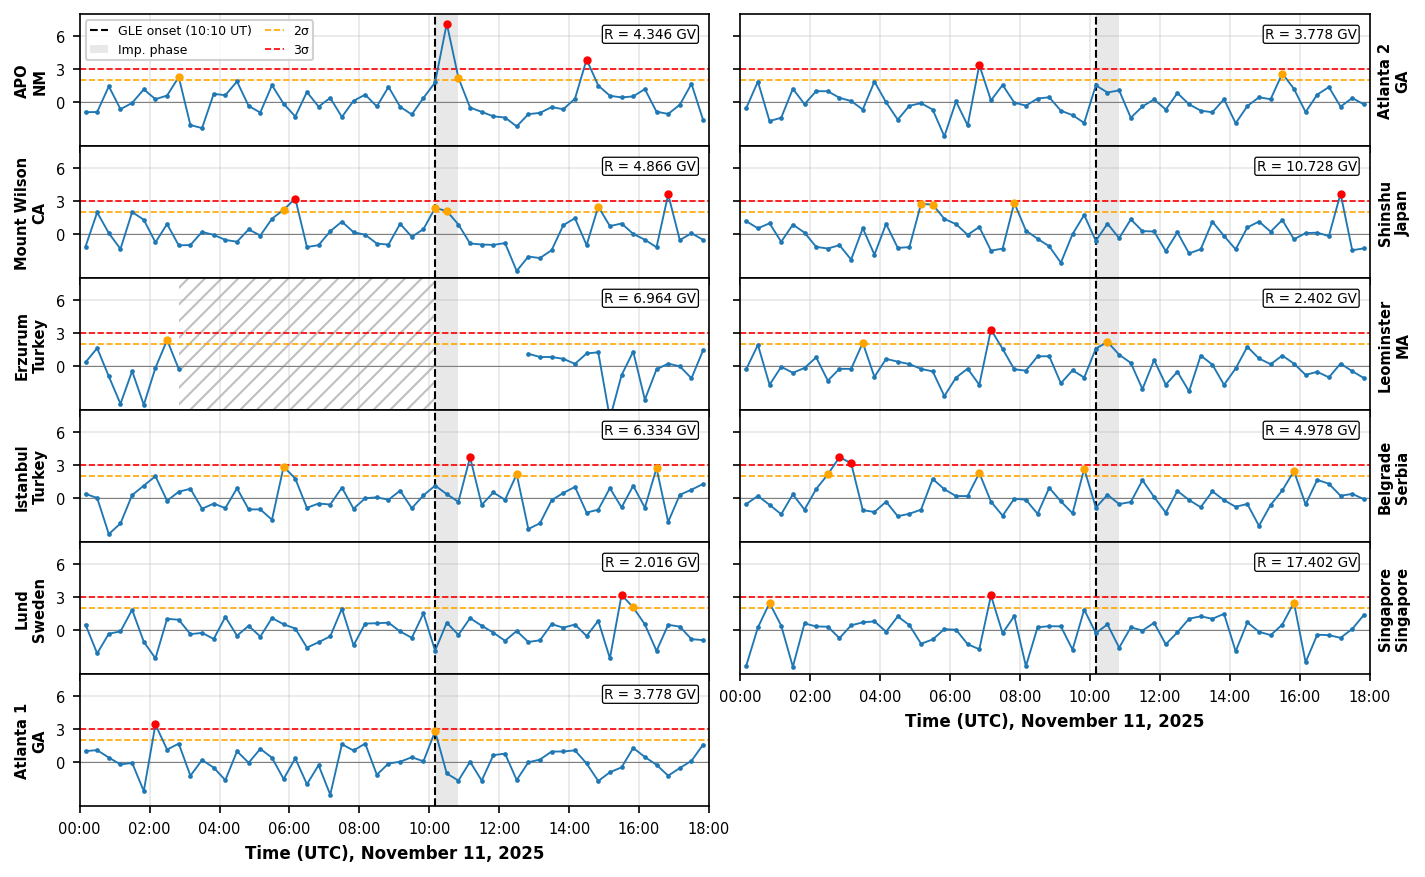

                               Rc_GV                 peak_time  baseline  observed  excess  sigma  significance                  status  frac_gt2  frac_gt3  n_win_bins  p_chance_2sig_window
station                                                                                                                                                                                      
Apache Point Observatory, NM   4.346 2025-11-11 10:30:00+00:00   479.037    510.35  31.313  4.385         7.141                assessed     0.050     0.007           3                 0.142
Mount Wilson, CA               4.866 2025-11-11 10:10:00+00:00   321.122    328.95   7.828  3.294         2.376                assessed     0.057     0.017           3                 0.161
Erzurum, Turkey                6.964                       NaT       NaN       NaN     NaN    NaN           NaN  no baseline (data gap)     0.066     0.015           0                   NaN
Istanbul, Turkey               6.334 2025-11-11 10

In [ ]:
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ---------- settings ----------
onset    = pd.Timestamp('2025-11-11 10:10:00', tz='UTC')   # GLE onset (Mishev et al. 2026)
imp_end  = pd.Timestamp('2025-11-11 10:50:00', tz='UTC')   # end of impulsive phase
PEAK_WIN = (onset, imp_end)     # window used for the peak search / table
t0 = pd.Timestamp('2025-11-11 00:00:00', tz='UTC')   # display start
t1 = pd.Timestamp('2025-11-11 18:00:00', tz='UTC')   # display end
WIN_H, GAP_H, MIN_PTS = 4.0, 0.33, 8
THR_2, THR_3 = 2.0, 3.0
CADENCE_MIN = 20
PANEL_H = 1.0                   # inches per row
FIG_W   = 10.0                  # figure width (inches)

stations_pc = ['APO\nNM', 'Mount Wilson\nCA', 'Erzurum\nTurkey', 'Istanbul\nTurkey',
               'Lund\nSweden', 'Atlanta 1\nGA', 'Atlanta 2\nGA',
               'Shinshu\nJapan', 'Leominster\nMA', 'Belgrade\nSerbia', 'Singapore\nSingapore']
rc_pc = [4.346, 4.866, 6.964, 6.334, 2.016, 3.778, 3.778, 10.728, 2.402, 4.978, 17.402]  # GV

assert len(filenames_pc) == len(stations_pc) == len(rc_pc) == len(labels_pc), \
    'filenames_pc, labels_pc, stations_pc and rc_pc must have the same length/order'

# ---------- helpers ----------
def find_gaps(t, cadence_min=CADENCE_MIN):
    dt = (t[1:] - t[:-1]).total_seconds() / 60.0
    return [(t[g], t[g + 1], dt[g]) for g in np.flatnonzero(dt > cadence_min)]

def sigma_deviation(t, y, win_h=WIN_H, gap_h=GAP_H, min_pts=MIN_PTS):
    """Deviation of each bin from a linear fit to the preceding win_h hours
    (excluding the last gap_h hours), in units of the fit's residual scatter."""
    th = ((t - t[0]).total_seconds() / 3600.0).values
    pred = np.full(len(y), np.nan)
    sig  = np.full(len(y), np.nan)
    for k in range(len(y)):
        m = (th >= th[k] - gap_h - win_h) & (th < th[k] - gap_h)
        if m.sum() < min_pts:
            continue
        p = np.polyfit(th[m], y[m], 1)
        pred[k] = np.polyval(p, th[k])
        sig[k]  = (y[m] - np.polyval(p, th[m])).std(ddof=2)
    return (y - pred) / sig, pred, sig

def style_panel(ax, label, rc=None, side='left'):
    ax.set_ylabel(label, fontweight='bold', fontsize=7)
    ax.tick_params(labelsize=7)
    if side == 'right':
        ax.yaxis.set_label_position('right')
        ax.tick_params(labelleft=False)        # shared σ scale: no duplicate tick labels
    ax.grid(True, alpha=0.3)
    if rc is not None:
        ax.text(0.98, 0.90, f'R = {rc:.3f} GV', transform=ax.transAxes,
                ha='right', va='top', fontsize=6.5,
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='k', lw=0.6))


w0, w1 = PEAK_WIN

n = len(filenames_pc)
nrows = int(np.ceil(n / 2))
fig, axs = plt.subplots(nrows, 2, figsize=(FIG_W, PANEL_H * nrows), dpi=150,
                        sharex=True, sharey=True)
axes = axs.T.ravel()            # fill column 1 top-to-bottom, then column 2
rows = []

for i in range(n):
    t, y = muon_filereader_20(pressure_corrected_folder + filenames_pc[i])
    t = pd.DatetimeIndex(pd.to_datetime(t, utc=True))
    y = np.asarray(y, dtype=float)

    gaps = find_gaps(t)
    for g0, g1, gmin in gaps:
        print(f'{labels_pc[i]}: gap {g0} -> {g1} ({gmin:.0f} min)')

    z, pred, sig = sigma_deviation(t, y)


    win   = (t >= w0) & (t <= w1)
    valid = win & np.isfinite(z)
    if valid.any():
        k = np.flatnonzero(valid)[np.nanargmax(z[valid])]
        peak = dict(peak_time=t[k], baseline=pred[k], observed=y[k],
                    excess=y[k] - pred[k], sigma=sig[k], significance=z[k],
                    status='assessed')
    else:
        peak = dict(peak_time=pd.NaT, baseline=np.nan, observed=np.nan,
                    excess=np.nan, sigma=np.nan, significance=np.nan,
                    status='no baseline (data gap)')
        print(f'{labels_pc[i]}: no valid trailing baseline in peak window')

    quiet = np.isfinite(z) & ~win
    n_ok  = int(quiet.sum())
    f2 = np.sum(z[quiet] > THR_2) / max(n_ok, 1)
    f3 = np.sum(z[quiet] > THR_3) / max(n_ok, 1)
    n_win = int(valid.sum())
    p_win = 1 - (1 - f2) ** n_win if n_win else np.nan
    rows.append(dict(station=labels_pc[i], Rc_GV=rc_pc[i], **peak,
                     frac_gt2=f2, frac_gt3=f3,
                     n_win_bins=n_win, p_chance_2sig_window=p_win))

    a = axes[i]
    v = (t >= t0) & (t <= t1)
    a.axvspan(onset, imp_end, color='gray', alpha=0.18, lw=0)
    a.axvline(onset, color='k', linestyle='--', lw=1)
    for g0, g1, _ in gaps:
        if g1 > t0 and g0 < t1:
            a.axvspan(max(g0, t0), min(g1, t1), facecolor='none', edgecolor='gray',
                      hatch='///', lw=0, alpha=0.5)
    a.axhline(THR_2, color='orange', ls='--', lw=0.8)
    a.axhline(THR_3, color='red',    ls='--', lw=0.8)
    a.axhline(0, color='gray', lw=0.5)
    a.plot(t[v], z[v], lw=0.9, marker='.', ms=2.5)
    m2 = v & (z > THR_2) & (z <= THR_3)
    m3 = v & (z > THR_3)
    a.plot(t[m2], z[m2], 'o', color='orange', ms=3)
    a.plot(t[m3], z[m3], 'o', color='red',    ms=3)
    a.set_ylim(-4, 8)
    a.set_yticks([0, 3, 6])
    style_panel(a, stations_pc[i], rc_pc[i],
                side='left' if i < nrows else 'right')

handles = [Line2D([0], [0], color='black',  lw=1,   ls='--'),
           Patch(facecolor='gray', alpha=0.18, edgecolor='none'),
           Line2D([0], [0], color='orange', lw=0.8, ls='--'),
           Line2D([0], [0], color='red',    lw=0.8, ls='--')]
axes[0].legend(handles, ['GLE onset (10:10 UT)', 'Imp. phase',
                         f'{THR_2:.0f}σ', f'{THR_3:.0f}σ'],
               loc=2, fontsize=6, ncol=2, framealpha=0.9,
               handlelength=1.5, borderpad=0.3, columnspacing=1.0)

for j in range(n, len(axes)):
    axes[j].axis('off')
xlab = 'Time (UTC), November 11, 2025'
axes[nrows - 1].set_xlabel(xlab, fontweight='bold', fontsize=8)
axes[n - 1].set_xlabel(xlab, fontweight='bold', fontsize=8)
axes[n - 1].tick_params(labelbottom=True)
for a in axes[:n]:
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
axs[0, 0].set_xlim(t0, t1)

fig.subplots_adjust(hspace=0, wspace=0.05, left=0.07, right=0.93, top=0.98, bottom=0.10)
plt.savefig('gle_sigma_deviation_zoom_2col.png', bbox_inches='tight')
plt.show()

gle_table = pd.DataFrame(rows).set_index('station')
pd.set_option('display.width', 240)
print(gle_table.round(3))